In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
# 1. Load and explore dataset
df = pd.read_csv("air_quality_dataset.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())


         Date          City    AQI  PM2.5   PM10  Ozone    NO2     CO    SO2  \
0  2024-10-16   Los Angeles  128.0  28.78  68.84  58.29  57.56  2.781  17.10   
1  2023-01-26  Jacksonville  111.0  28.73  61.93  59.00  35.73  1.810  16.33   
2  2023-10-09       Houston   91.0  20.04  47.10  66.20  43.91  2.566  15.27   
3  2023-08-17       Chicago  108.0  23.39  47.90  62.85  48.89  2.332  18.49   
4  2023-04-15        Austin  106.0  26.51  56.08  62.38    NaN  1.867  15.93   

   Temperature  Humidity  
0          3.4      82.2  
1         17.0      36.0  
2          1.0      68.6  
3          9.4      85.7  
4         17.3      48.7  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5583 entries, 0 to 5582
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         5583 non-null   object 
 1   City         5583 non-null   object 
 2   AQI          5472 non-null   float64
 3   PM2.5        5486 non-null   float6

In [5]:
# 2. Prepare data
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
cols = ["PM2.5", "PM10", "CO", "AQI"]


In [7]:
for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

df = df.dropna(subset=["Date"]).sort_values("Date")

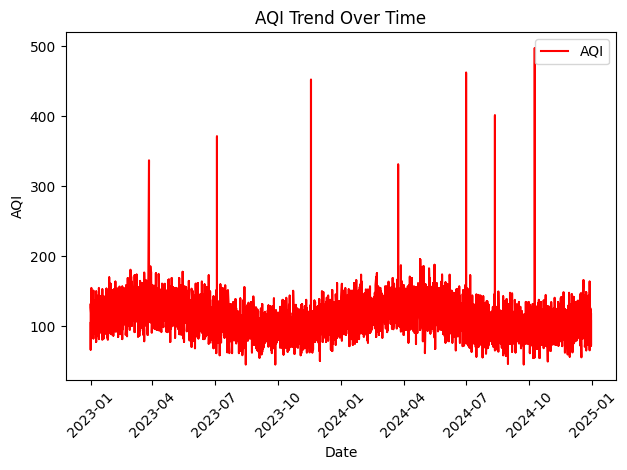

In [9]:
# 3. Plot overall AQI trend
plt.plot(df["Date"], df["AQI"], label="AQI", color="red")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.title("AQI Trend Over Time")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


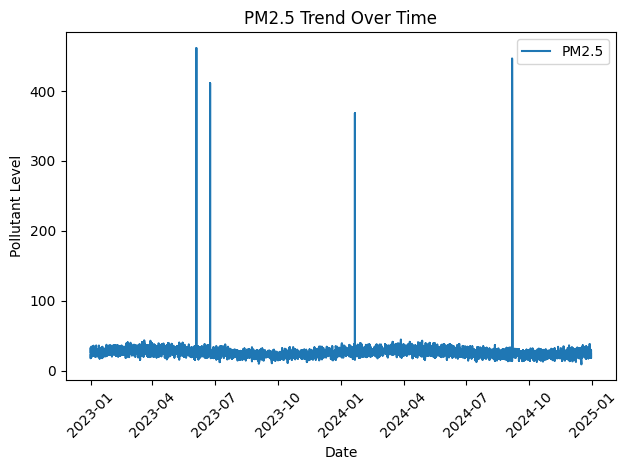

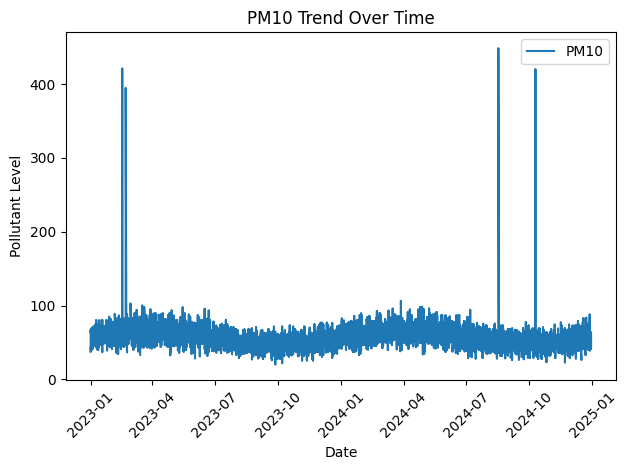

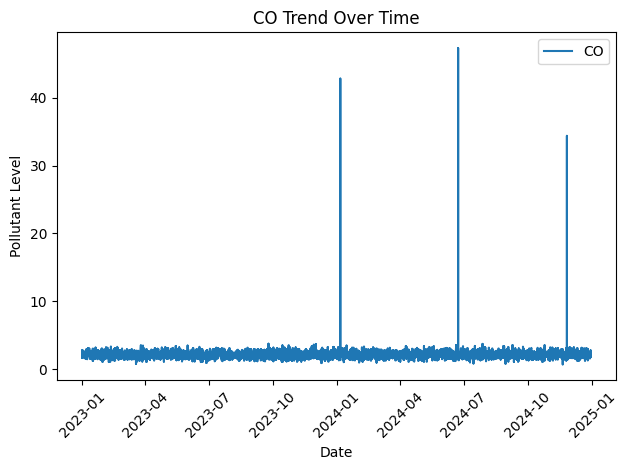

In [11]:
# 4. Plot individual pollutant trends
for col in ["PM2.5", "PM10", "CO"]:
    plt.plot(df["Date"], df[col], label=col)
    plt.xlabel("Date")
    plt.ylabel("Pollutant Level")
    plt.title(col + " Trend Over Time")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


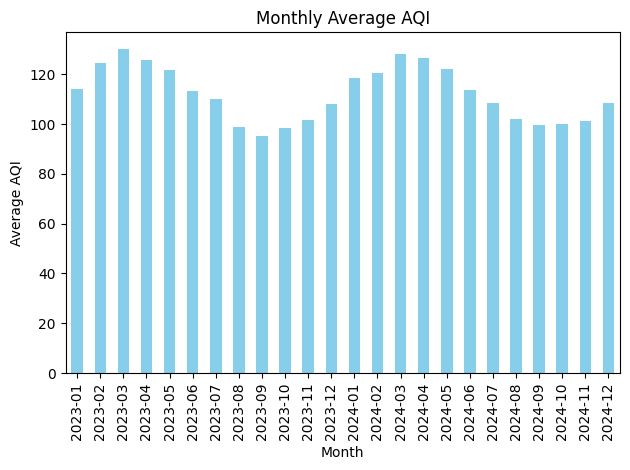

In [13]:
# 5. Compare average AQI by month using a bar plot
df["Month"] = df["Date"].dt.to_period("M").astype(str)
df.groupby("Month")["AQI"].mean().plot(kind="bar", color="skyblue")
plt.ylabel("Average AQI")
plt.title("Monthly Average AQI")
plt.tight_layout()
plt.show()


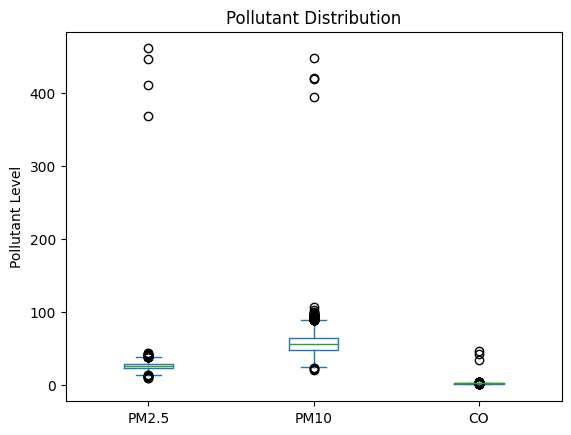

In [15]:
# 6. Box plot to compare pollutant distributions
df[["PM2.5", "PM10", "CO"]].plot(kind="box")
plt.title("Pollutant Distribution")
plt.ylabel("Pollutant Level")
plt.show()

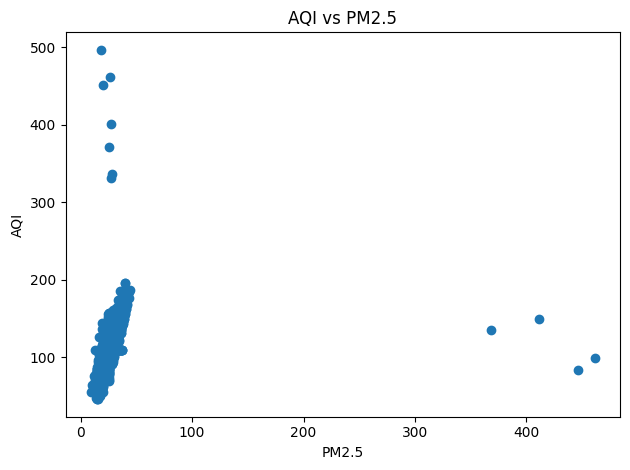

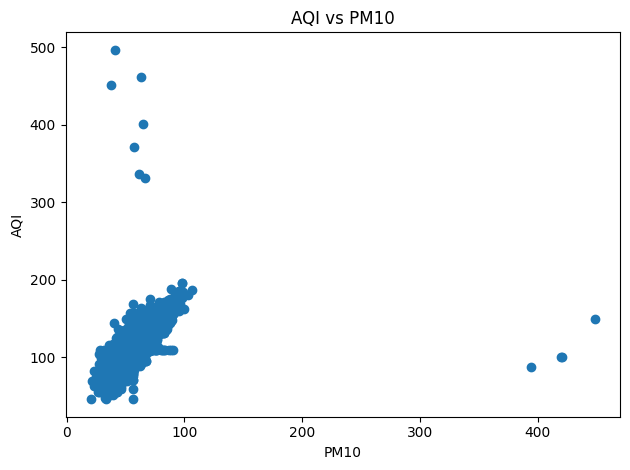

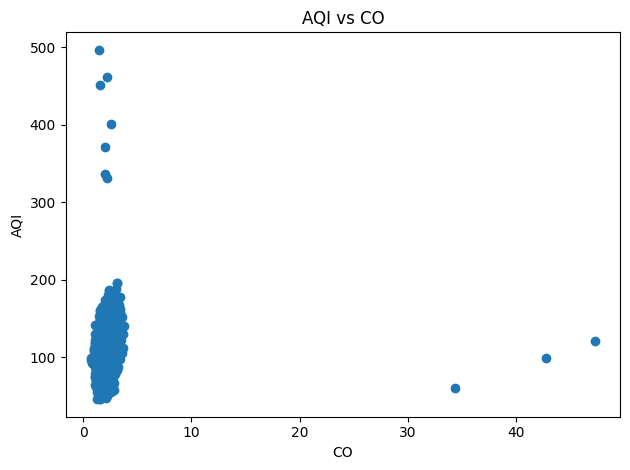

In [17]:

# 7. Scatter plots: AQI versus each pollutant
for col in ["PM2.5", "PM10", "CO"]:
    plt.scatter(df[col], df["AQI"], label=col)
    plt.xlabel(col)
    plt.ylabel("AQI")
    plt.title("AQI vs " + col)
    plt.tight_layout()
    plt.show()

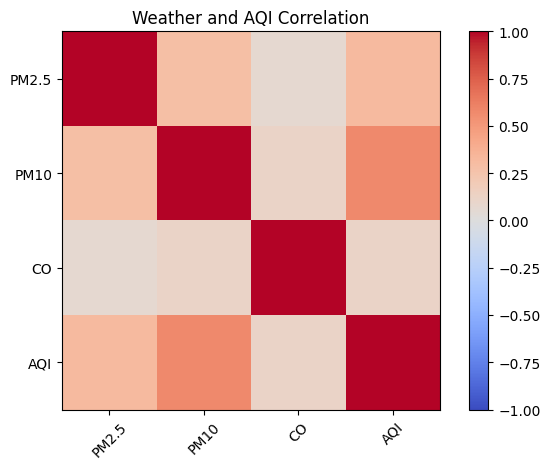

In [19]:
# 8. Correlation heatmap using Matplotlib
plt.imshow(df[cols].corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(cols)), cols, rotation=45)
plt.yticks(range(len(cols)), cols)
plt.title("Weather and AQI Correlation")
plt.tight_layout()
plt.show()